---
title: Annotations
subtitle: "DS 2023 | Communicating with Data"
---

<img src="https://virginia.box.com/shared/static/va5g1yo77lhur79jb11ilpcmiew3cao8.png" 
    style="height:650px;"/>

## Overview

Effective visualizations use **language and visual symbols** to direct the reader's attention to what is salient in a visualization.

There are two major areas of concern:

**Labeling**

- All parts of a plot or group of plots should be properly and effectively labels.

- Parts include axes, ticks, geometries (dots, bars, etc.), and the figure itself. 

- Sometimes this means **removing text**.

- In all cases, the goal is to make the plot completely **legible** and **intelligble**.

**Adding context**

- Annotation includes providing information needed to properly interpret the visualization.

- Information includes  **data sources**, **units of measurement**, **scales**, etc.

**Emphasizing**

- Annotation also include the use of **visual devices and text labels**.

- These things often are often **overlaid on the plot** to highlight its part.

- Examples inclide a **region** of a scatter plot or **a high point** in a trend.  


## Kinds of annotation

Among the specific devices used to annotate an image are:

- **text**: a label placed anywhere on the plot.
- **arrows**: used to direct attention to a specific element.
- **callouts**: text with an arrow pointing to a feature.
- **reference lines**: a vertical or horizontal line to indicate a threshold, an average, a target, a date, etc.
- **regions**: a shaded band for a period, a range, or a gap between two series, etc..
- **labels on marks**: text used to show the actual value printed on each bar, etc.
- **shapes**: a box or ellipse drawn around a cluster, etc.
- **emphasis**: one series in color while the others are gray, etc.
- **figure-level marks**: a title over several panels, panel letters, lines that connect one panel to another.

## Some specific use cases

- **Marking an event**: a recession, a policy change, a pandemic year on a time series.
- **Labeling an extreme**: the busiest month, the largest outlier, the record high.
- **Showing a threshold**: break-even, a passing grade, a legal limit, the mean.
- **Comparing to a range**: one country against the band formed by all the others.
- **Reading exact values**: counts printed on bars when readers need the numbers.
- **Guiding a multi-panel figure**: panel letters, a shared title, a zoom from an overview to a detail.

## Set Up

We will use two wide tables throughout, shaped as in earlier notebooks.

Each has years in the index and one column per series.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

healthexp = sns.load_dataset('healthexp')
flights = sns.load_dataset('flights')
penguins = sns.load_dataset('penguins').dropna()
mpg = sns.load_dataset('mpg')

life = healthexp.pivot(index='Year', columns='Country', values='Life_Expectancy')
passengers = flights.pivot(index='year', columns='month', values='passengers')
annual = passengers.sum(axis=1)

## Understanding how to locate annotations

To actually place an annotation on a figure, we need to know how Matplotlib handles **locations**.

There are actually **three coordinate systems** in play.

| System | Runs from | Use it when the annotation belongs to... |
|---|---|---|
| **Data** (the default) | the axis values, such as years and passengers | a data point or value |
| **Axes fraction** | (0, 0) at the bottom left of the axes to (1, 1) at the top right | a position in the plot box, such as a corner |
| **Figure fraction** | (0, 0) to (1, 1) across the whole figure | the figure as a whole, across panels |

Let's put one label in each system.

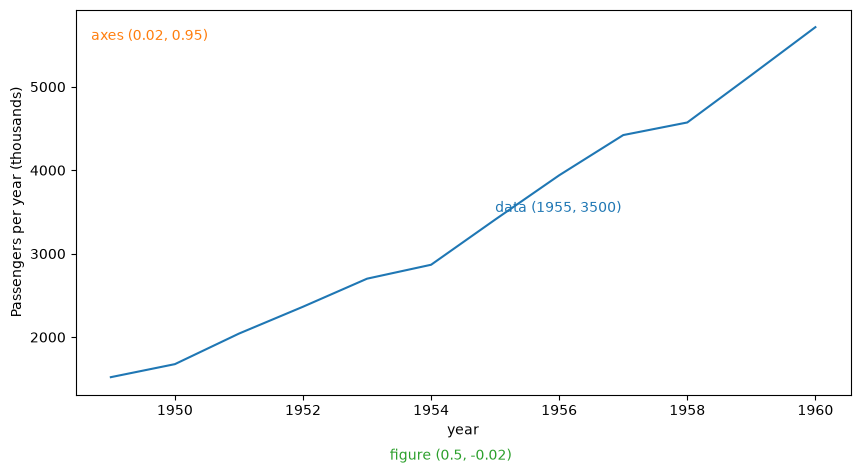

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))

annual.plot(ax=ax, color='tab:blue')

# Data 
ax.text(1955, 3500, 'data (1955, 3500)', color='tab:blue')

# Axes
ax.text(0.02, 0.95, 'axes (0.02, 0.95)', transform=ax.transAxes, color='tab:orange', va='top')

# Figure
fig.text(0.5, -0.02, 'figure (0.5, -0.02)', ha='center', color='tab:green')

ax.set_ylabel('Passengers per year (thousands)')

plt.show()

The **blue label** is tied to the **data**.

- If the axis limits change, it moves with the line.

The **orange label** is tied to the **axes** box, through `transform=ax.transAxes`.

- By default, the x and y you give `ax.text()` are in data coordinates, i.e. the position of (x,y) in the cartesian plane.

- With `transform=ax.transAxes`, the numbers are read as fractions of the axes.

- So, `(0, 0)` is the bottom-left corner of the plot box and `(1, 1)` is the top-right/

The **green label** is tied to the **figure**, and sits below the axes entirely.

```{tip}
Use data coordinates for anything that points at the data.

Use axes or figure coordinates for anything that labels the plot itself, such as a note, a source line, or a panel letter.
```

## Text

The function `ax.text(x, y, s)` writes the string `s` at the point `(x, y)`.

It is the simplest annotation, and every other text annotation is built on it.

Its most useful parameters control alignment and appearance.

| Parameter | Does |
|---|---|
| `ha` | horizontal alignment of the text *relative to the point*: `'left'`, `'center'`, `'right'` |
| `va` | vertical alignment: `'bottom'`, `'center'`, `'top'`, `'baseline'` |
| `fontsize`, `fontweight`, `color` | appearance |
| `rotation` | angle in degrees |
| `bbox` | a dictionary describing a box behind the text |
| `transform` | the coordinate system, such as `ax.transAxes` |

Alignment confuses almost everyone at first.

`ha='left'` does not move the text to the left.

It puts the *left edge* of the text at the point.

Let's see all three settings at once, with a dot marking the point.

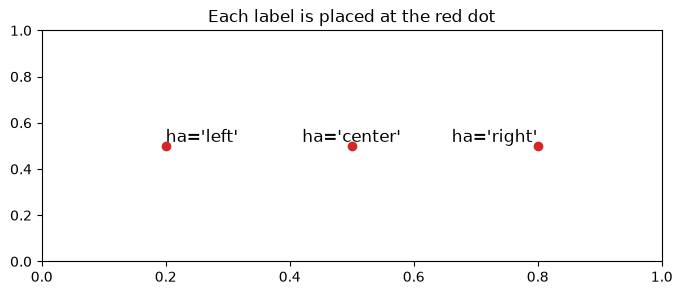

In [30]:
fig, ax = plt.subplots(figsize=(8, 3))

for x, ha in zip([0.2, 0.5, 0.8], ['left', 'center', 'right']):
    ax.plot(x, 0.5, 'o', color='tab:red')
    ax.text(x, 0.5, f"ha='{ha}'", ha=ha, va='bottom', fontsize=12)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title('Each label is placed at the red dot')
plt.show()

### Direct labeling

A common use of `text()` is to label lines directly, at their ends, instead of with a legend.

The reader no longer has to match colors between the legend and the plot.

Here is life expectancy, with each country labeled at its last year.

In [31]:
life.head()

Country,Canada,France,Germany,Great Britain,Japan,USA
Year,,,,,,
1970,NaN,72.2,70.6,71.9,72.0,70.9
1971,72.8,NaN,70.8,71.9,72.9,71.2
1972,NaN,NaN,71.0,NaN,73.2,71.2
1973,NaN,NaN,71.3,NaN,73.4,71.4
1974,NaN,NaN,71.5,NaN,73.7,72.0


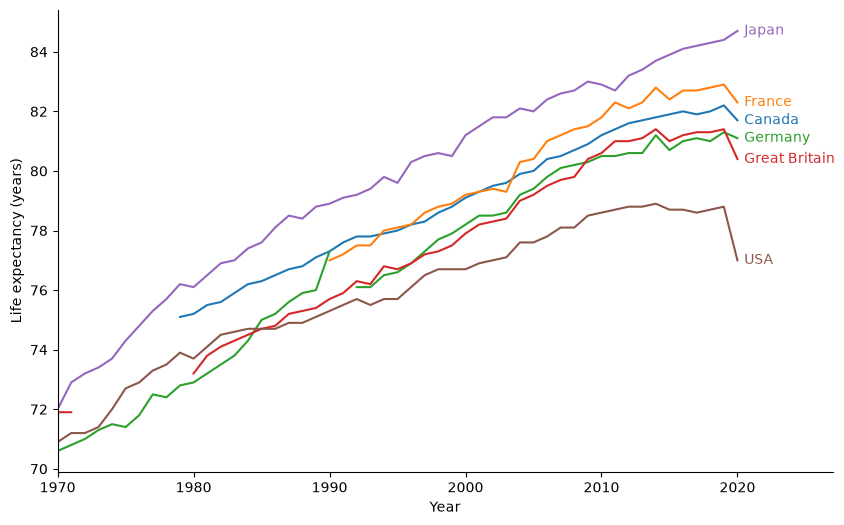

In [35]:
fig, ax = plt.subplots(figsize=(10, 6))

life.plot(ax=ax, legend=False)

# Loop through the lines of the axes object
for line in ax.lines:
    color = line.get_color()
    label = line.get_label()
    x = line.get_data()[0][-1] # last value in the x series
    y = line.get_data()[1][-1] # last value in the y series
    ax.text(x + .5, y, label, color=color, va='center')

ax.set_xlim(1970, 2027)
ax.set_ylabel('Life expectancy (years)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The `.plot()` method returns a list of the lines it drew.

We can ask for the color of each line with `get_color()` and give the label the same color.

Direct labels work best when the line ends are well separated.

When they are not, you have to nudge the labels by hand or fall back on a legend.

### Text in a box

The `bbox` parameter of `ax.text()` draws a box behind the text.

It is useful for notes that sit on top of data, where the box keeps the text readable.

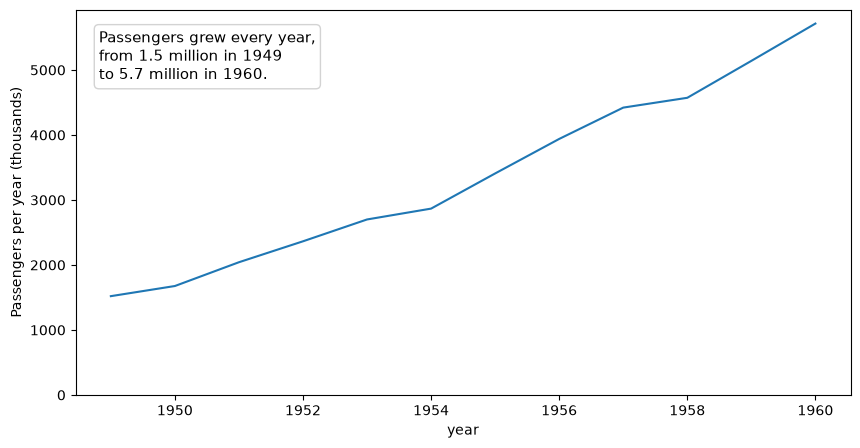

In [42]:
fig, ax = plt.subplots(figsize=(10, 5))

annual.plot(ax=ax, color='tab:blue')

ax.text(
    0.03, # x
    0.95, # y 
    'Passengers grew every year,\nfrom 1.5 million in 1949\nto 5.7 million in 1960.', # text
    
    transform=ax.transAxes, # use Axes location not data points
    va='top', # Vertically align to the top
    fontsize=11,
    
    # Define a bounding box
    bbox=dict(
        boxstyle='round', 
        facecolor='white', 
        edgecolor='lightgray'
    )
)

ax.set_ylim(0)
ax.set_ylabel('Passengers per year (thousands)')
plt.show()

## Callouts with `annotate()`

The `ax.annotate()` function is `text()` with an arrow.

It takes two positions:

- `xy`, a tuple of the the point being annotated, i.e. where the arrow ends,
- `xytext`, a tuple of the place where the text goes, i.e. where the arrow starts.

The arrow is drawn only if we pass a dictionary of properties to `arrowprops`.

Here we point to the busiest month in the `flights` dataset.

In [102]:
# Create a series out of the year and month converted to a datetime 
monthly = flights.assign(date=pd.to_datetime(flights.year.astype(str) + '-' + flights.month.astype(str), format='%Y-%b'))
monthly = monthly.set_index('date').passengers
monthly.head()

date
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Name: passengers, dtype: int64

1960-07-01 00:00:00 622


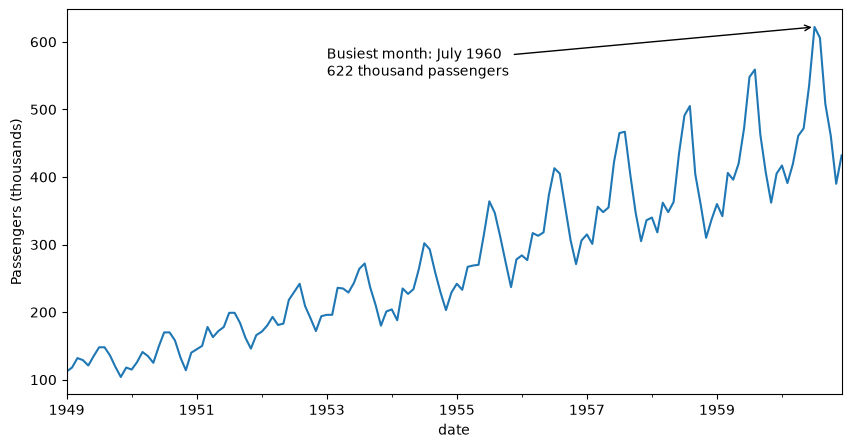

In [103]:
# Pull out the coordinates you want to identify
peak_date = monthly.idxmax()
peak_value = monthly.max()

# Show the coordinates
print(peak_date, peak_value)

# Plot the line
fig, ax = plt.subplots(figsize=(10, 5))
monthly.plot(ax=ax, color='tab:blue')

# Annotate the point
ax.annotate(f'Busiest month: {peak_date:%B %Y}\n{peak_value} thousand passengers',
            xy=(peak_date, peak_value),
            xytext=(pd.Timestamp('1953-01-01'), 550),
            arrowprops=dict(arrowstyle='->', color='black'))

ax.set_ylabel('Passengers (thousands)')
plt.show()

Notice that we did not type the date or the number into the label.

We computed them with `idxmax()` and `max()`, so the annotation stays correct if the data change.

```{important}
Compute annotation positions and values from the data whenever you can.

A hard-coded arrow points to the right place only for the data it was written for.
```

### Using offsets instead of positions

Choosing `xytext` in data coordinates can be awkward, because we must think in dates and passengers to place a label.

Often it is easier to say *how far* the text should be from the point, in screen units.

`textcoords='offset points'` does this.

A **point** is 1/72 of an inch, the unit of font sizes.

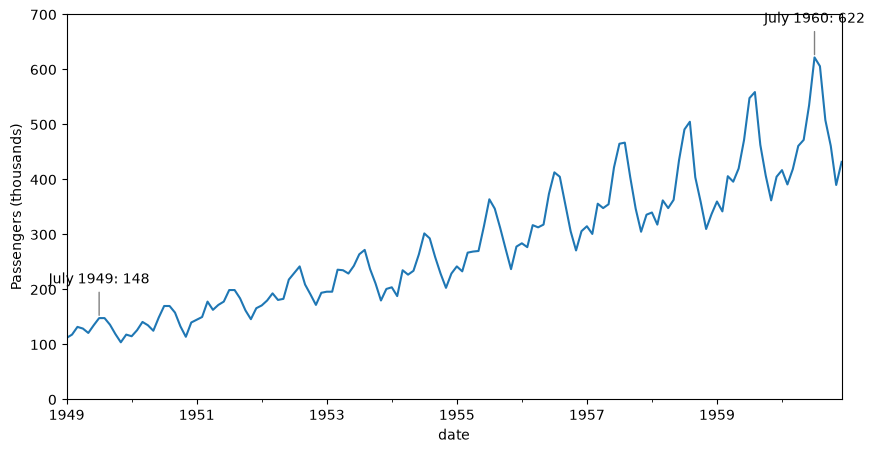

In [104]:
fig, ax = plt.subplots(figsize=(10, 5))
monthly.plot(ax=ax, color='tab:blue')

for year in [1949, 1960]:
    july = pd.Timestamp(f'{year}-07-01')
    ax.annotate(f'July {year}: {monthly[july]}',
                xy=(july, monthly[july]),
                xytext=(0, 25), 
                textcoords='offset points',
                ha='center',
                arrowprops=dict(arrowstyle='-', color='gray'))

ax.set_ylim(0, 700)
ax.set_ylabel('Passengers (thousands)')
plt.show()

Each label sits 25 points directly above its point, whatever the axis scales are.

The July peak more than quadrupled in twelve years.

### Arrow styles

`arrowprops` accepts many options.

The two we use most are `arrowstyle` and `connectionstyle`, which bends the arrow.

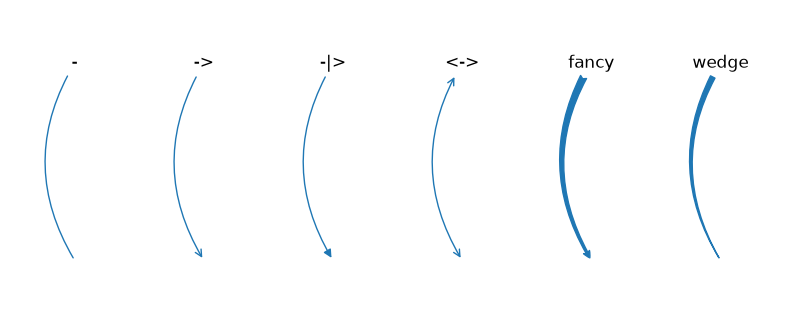

In [107]:
styles = ['-', '->', '-|>', '<->', 'fancy', 'wedge']

fig, ax = plt.subplots(figsize=(10, 4))

for i, style in enumerate(styles):
    ax.annotate(
        style, 
        xy=(i, 0), 
        xytext=(i, 1),        
        ha='center', 
        fontsize=12,
        arrowprops=dict(
            arrowstyle=style, 
            color='tab:blue',
            connectionstyle='arc3, rad=0.3'
        )
    )

ax.set_xlim(-0.5, len(styles) - 0.5)
ax.set_ylim(-0.3, 1.3)
ax.set_axis_off()
plt.show()

`'arc3,rad=0.3'` curves each arrow; `rad=0` is straight.

A gentle curve can route an arrow around data that a straight arrow would cross.

## Reference lines

A reference line marks a value that is not in the data but helps us read it: an average, a target, a date.

| Method | Draws |
|---|---|
| `ax.axhline(y)` | a horizontal line across the whole axes |
| `ax.axvline(x)` | a vertical line across the whole axes |
| `ax.hlines(y, xmin, xmax)` | horizontal segments with set ends, one or many |
| `ax.vlines(x, ymin, ymax)` | vertical segments with set ends, one or many |
| `ax.axline(xy1, xy2)` or `ax.axline(xy1, slope=m)` | an infinite line through a point at any angle |

Lines are usually paired with `text()`.

Here are penguin body masses, with the overall mean as a reference.

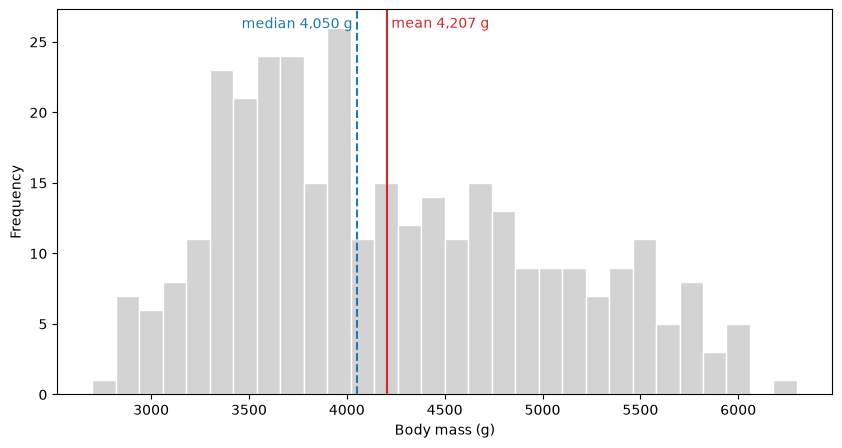

In [122]:
fig, ax = plt.subplots(figsize=(10, 5))

penguins['body_mass_g'].plot.hist(bins=30, color='lightgray', edgecolor='white')

mean = penguins.body_mass_g.mean()
median = penguins.body_mass_g.median()

# Create a vertical line with text to show mean
ax.axvline(mean, color='tab:red')
ax.text(mean, 0.98, f' mean {mean:,.0f} g', color='tab:red',
        transform=ax.get_xaxis_transform(), va='top')

# Create a vertical line with text to show median
ax.axvline(median, color='tab:blue', linestyle='--')
ax.text(median, 0.98, f'median {median:,.0f} g ', color='tab:blue',
        transform=ax.get_xaxis_transform(), va='top', ha='right')

ax.set_xlabel('Body mass (g)')
plt.show()

The `transform` argument in the `text()` uses the argument `ax.get_xaxis_transform()`.

This lets the user specify a location along the line.

- In the case of a vertical lines, a value of $0$ means at the bottom and $1$ means at the top.

- So, with a value of $.98$,  each label sits at its line's x value, near the top of the plot, whatever the heights of the bars.

Notice that the mean is to the right of the median.

That is what we expect from a right-skewed distribution.

### A diagonal reference

Use `axline()` to draw lines at any angle.

In a scatter plot of two measurements in the same units, the line y = x is often the most useful reference.

Here is Japan's life expectancy against the USA's, one point per year.

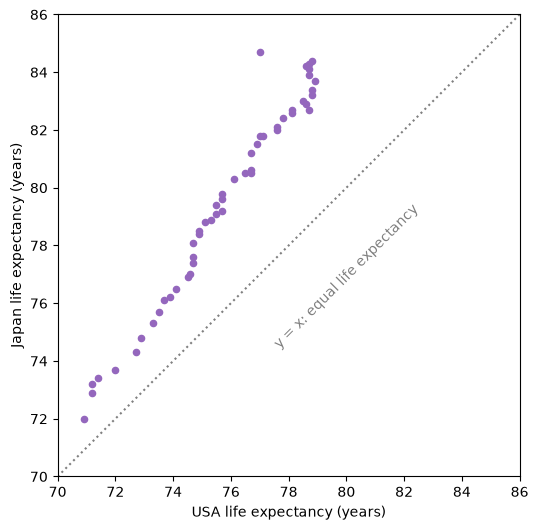

In [130]:
fig, ax = plt.subplots(figsize=(6, 6))

life.plot.scatter(x='USA', y='Japan', color='tab:purple', ax=ax)

ax.axline((75, 75), slope=1, color='gray', linestyle=':')
ax.text(80, 79.5, 'y = x: equal life expectancy', color='gray', rotation=45, ha='center', va='top')

ax.set_xlim(70, 86)
ax.set_ylim(70, 86)
ax.set_xlabel('USA life expectancy (years)')
ax.set_ylabel('Japan life expectancy (years)')
ax.set_aspect('equal')

plt.show()

Notice that every point is above the line.

So in every year with data, Japan's life expectancy was higher than the USA's.

The distance from the line is the size of the gap, and it grows as we move up and to the right.

One point jumps far to the left of its neighbors: 2020, when the USA lost almost two years and Japan did not.

Without the line, the eye has nothing to measure against.

## Regions

Some annotations mark an **area** rather than a value.

### Spans

- `ax.axvspan(xmin, xmax)` shades a vertical band across the whole height of the axes.

- `ax.axhspan(ymin, ymax)` shades a horizontal one.

Here is USA life expectancy, with the first pandemic year shaded.

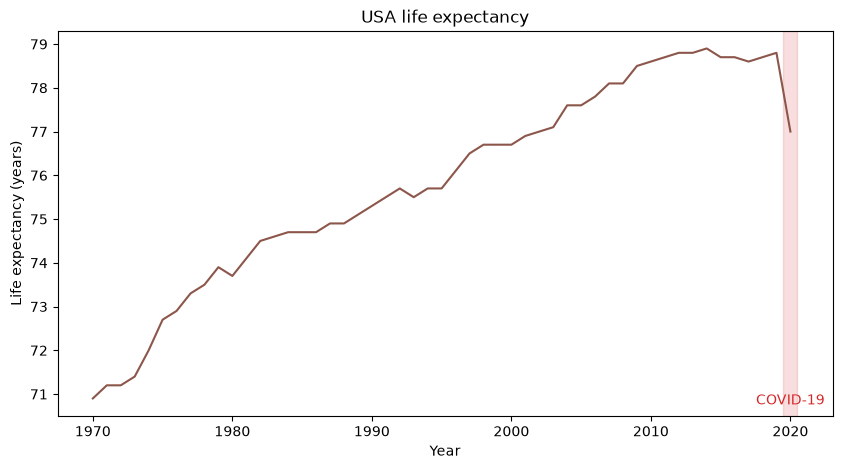

In [133]:
fig, ax = plt.subplots(figsize=(10, 5))

life.USA.plot(ax=ax, color='tab:brown')

ax.axvspan(2019.5, 2020.5, color='tab:red', alpha=0.15)
ax.text(2020, 0.03, 'COVID-19', transform=ax.get_xaxis_transform(),
        ha='center', color='tab:red')

ax.set_ylabel('Life expectancy (years)')
ax.set_title('USA life expectancy')
plt.show()

The span runs from 2019.5 to 2020.5 so that it is centered on the 2020 data point.

### Bands between curves with `fill_between()`

`ax.fill_between(x, y1, y2)` shades the region between two curves.

If we leave out `y2`, it fills down to 0.

We used it in *Area Charts* to draw areas.

Here we use it to annotate: to show a **range** against which one series can be compared.

Let's shade the band from the lowest to the highest life expectancy among the five other countries, and draw the USA on top.

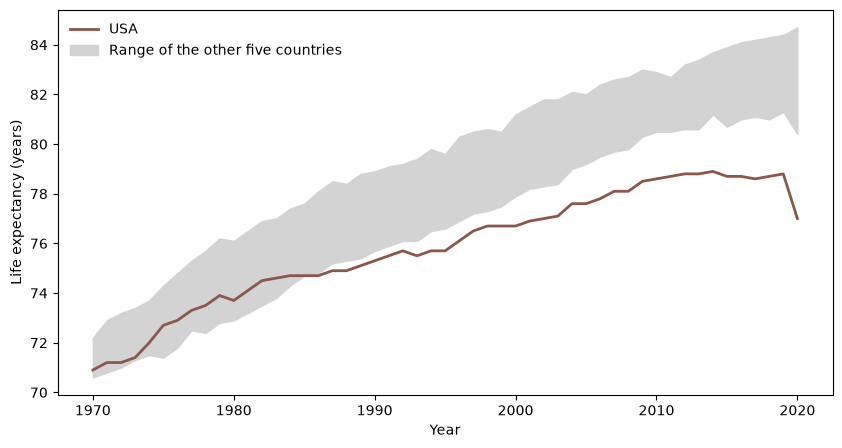

In [149]:
fig, ax = plt.subplots(figsize=(10, 5))

life['USA'].plot(color='tab:brown', linewidth=2, label='USA')
others = life.drop(columns='USA')
ax.fill_between(
    others.index, 
    others.min(axis=1), 
    others.max(axis=1),            
    color='lightgray', 
    label='Range of the other five countries'
)

ax.legend(loc='upper left', frameon=False)
ax.set_ylabel('Life expectancy (years)')
plt.show()

Here we can see something that no single line shows.

Until the mid-1980s, the USA sat inside the range of the others.

Then it fell below it and never came back.

What year does the USA leave the band?

You can find it with `(life.USA < others.min(axis=1))`.

### Shading a gap with `where`

`fill_between()` has a `where` parameter that shades only where a condition is true.

With it, we can color the *gap* between two series differently depending on which is higher.

The USA is below the other five on average in every year, so that comparison would be all one color.

Let's compare the USA with Germany instead.

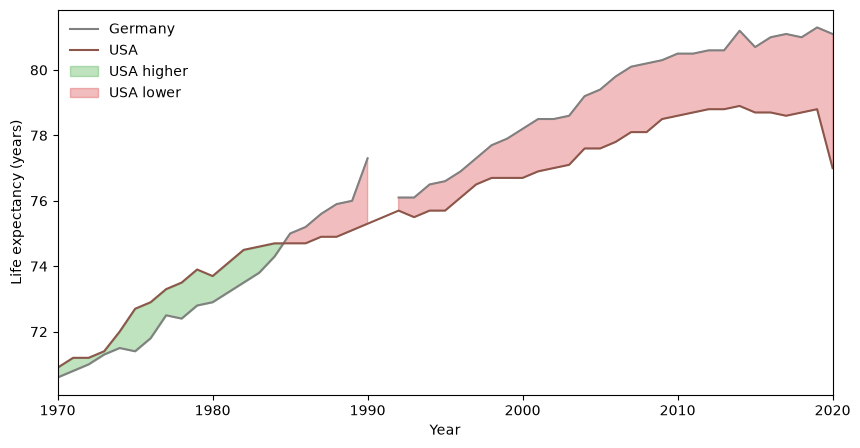

In [150]:
fig, ax = plt.subplots(figsize=(10, 5))

life[['Germany', 'USA']].plot(ax=ax, color=['gray','tab:brown'])

ax.fill_between(life.index, life.USA, life.Germany,
                where=life.USA >= life.Germany, interpolate=True,
                color='tab:green', alpha=0.3, label='USA higher')
ax.fill_between(life.index, life.USA, life.Germany,
                where=life.USA < life.Germany, interpolate=True,
                color='tab:red', alpha=0.3, label='USA lower')

ax.set_xlim(1970, 2020)
ax.legend(loc='upper left', frameon=False)
ax.set_ylabel('Life expectancy (years)')
plt.show()

Until 1984, Americans could expect to live slightly longer than Germans.

From 1985 on, the order reversed, and the gap has widened ever since.

The spike in 1990 and the break in 1991 come from the German data around reunification, not from a real change in lifespans.

An odd feature like this is something to check, and perhaps annotate, before we draw attention to it.

`interpolate=True` finds where the two lines cross, so the colors meet exactly at the crossing instead of at the nearest year.

This is the **difference chart** from *Area Charts*, which goes back to William Playfair's 1786 chart of England's trade with Denmark and Norway.

Here it is doing the work of an annotation: the color tells us what to read in the gap.

```{note}
`fill_betweenx()` does the same thing with the axes swapped, filling between two x values at each y.
```

## Labels on marks

When readers need exact values, we can print them on the marks.

For bar charts, `ax.bar_label()` does this in one call.

It takes the **container** of bars that a bar plot returns, which Pandas stores in `ax.containers`.

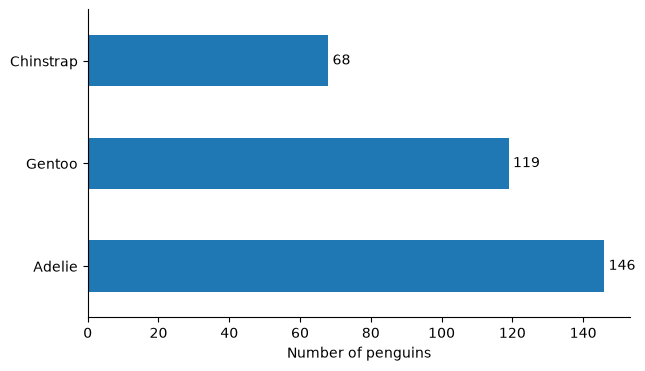

In [154]:
counts = penguins.species.value_counts()

fig, ax = plt.subplots(figsize=(7, 4))

counts.plot.barh(ax=ax, color='tab:blue')

ax.bar_label(ax.containers[0], padding=3)

ax.set_xlabel('Number of penguins')
ax.set_ylabel('')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

`bar_label()` also takes a `fmt` string, or a list of `labels` for full control.

Here are the same bars labeled with percentages.

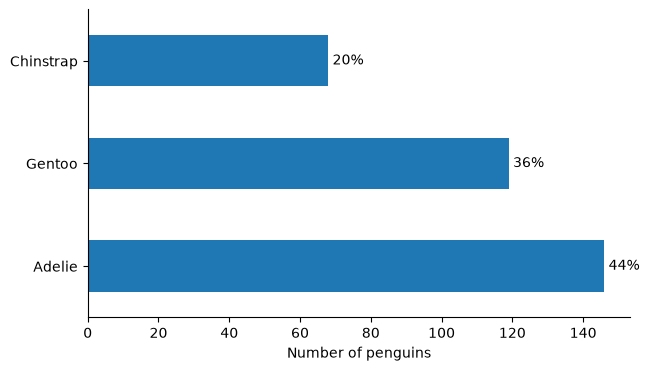

In [156]:
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot.barh(ax=ax, color='tab:blue')

percents = (counts / counts.sum()).map('{:.0%}'.format)
ax.bar_label(ax.containers[0], labels=percents, padding=3)

ax.set_xlabel('Number of penguins')
ax.set_ylabel('')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

For other plots, we label points with `text()` or `annotate()` in a loop.

Here is a scatter plot of car weight against fuel economy, with the five most efficient cars named.

`offset points` keeps each label a little to the right of its point.

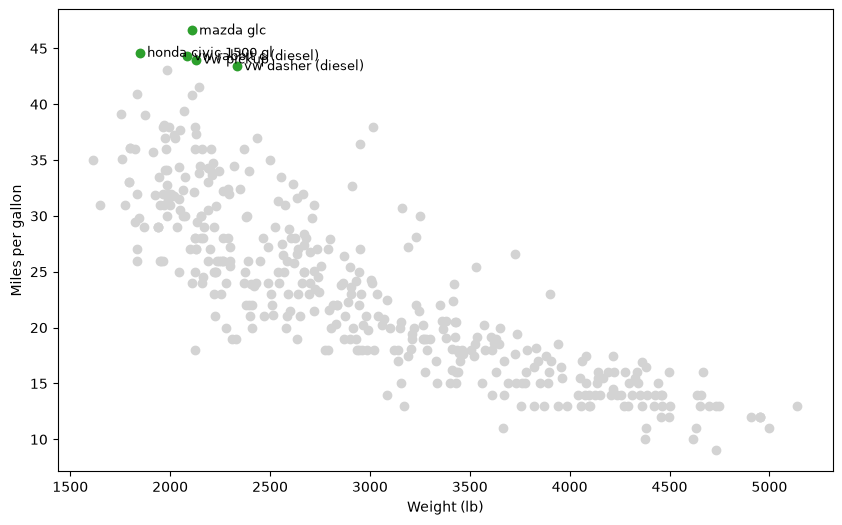

In [157]:
best = mpg.nlargest(5, 'mpg')

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(mpg.weight, mpg.mpg, color='lightgray')
ax.scatter(best.weight, best.mpg, color='tab:green')

for _, car in best.iterrows():
    ax.annotate(car['name'], xy=(car.weight, car.mpg),
                xytext=(5, 0), textcoords='offset points', va='center', fontsize=9)

ax.set_xlabel('Weight (lb)')
ax.set_ylabel('Miles per gallon')
plt.show()

Labels that overlap each other are the usual problem with this approach.

Label only the points that matter to the story, and nudge the rest by hand.

## Shapes with patches

Sometimes we want to point at a *group* of points, not a single one.

The `matplotlib.patches` module provides shapes such as `Rectangle`, `Circle`, `Ellipse`, and `Polygon`.

We create a shape, then add it to the axes with `ax.add_patch()`.

Here we circle the Gentoo penguins, which form their own cluster in the bill measurements.

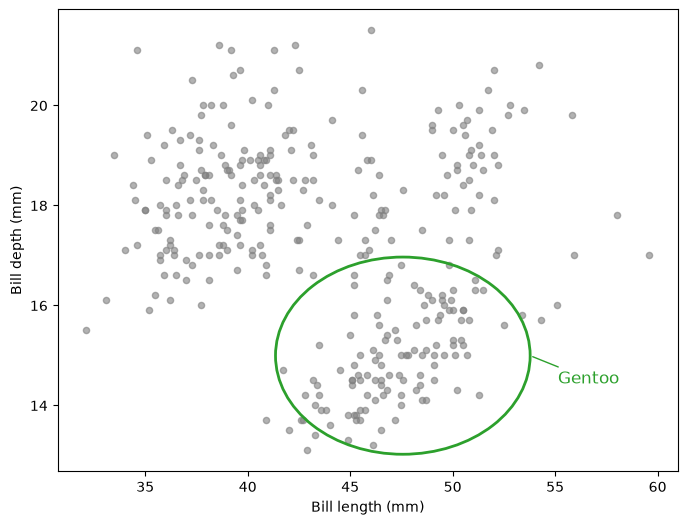

In [164]:
from matplotlib.patches import Ellipse

gentoo = penguins.query("species == 'Gentoo'")

# Get the center of the ellipse to be drawn
center = (
    gentoo.bill_length_mm.mean(), 
    gentoo.bill_depth_mm.mean()
)

fig, ax = plt.subplots(figsize=(8, 6))
penguins.plot.scatter('bill_length_mm', 'bill_depth_mm', color='gray', alpha=0.6, ax=ax)

# Define the shape
ellipse = Ellipse(
    center, 
    width=4 * gentoo.bill_length_mm.std(), 
    height=4 * gentoo.bill_depth_mm.std(),
    fill=False, 
    edgecolor='tab:green', 
    linewidth=2
)

# Put the shape in the plot
ax.add_patch(ellipse)

# Label the shape
ax.annotate(
    'Gentoo', 
    xy=(center[0] + 2 * gentoo.bill_length_mm.std(), center[1]),
    xytext=(20, -20), 
    textcoords='offset points', 
    color='tab:green', 
    fontsize=12,
    arrowprops=dict(arrowstyle='-', color='tab:green')
)

ax.set_xlabel('Bill length (mm)')
ax.set_ylabel('Bill depth (mm)')
plt.show()

The ellipse is centered on the Gentoo means and spans two standard deviations each way.

So it is computed from the data, not drawn by eye.

Notice that we did not color the points by species.

The shape alone points the reader to one group, and lets the others stay in the background.

````{admonition} How the line meets the ellipse
:class: tip

The line touches the ellipse exactly because its end point is calculated, not placed by eye.

The ellipse is 4 standard deviations wide, so it reaches 2 standard deviations to each side of its center.

Its rightmost point is therefore at the mean bill length plus 2 standard deviations, at the height of the center.

That is exactly the `xy` we gave `annotate()`:

```python
xy=(center[0] + 2 * gentoo.bill_length_mm.std(), center[1])
```

Because the ellipse and the end of the line are computed from the same numbers, they stay joined if the data change.

The label is placed relative to that point: `xytext=(20, -20)` with `textcoords='offset points'` puts it 20 points to the right and 20 points below, at any figure size.

Matplotlib also trims the line at both ends.
At the label, it stops at the edge of the text's bounding box, so it never runs through the letters.
At the ellipse, it stops 2 points short of `xy` by default (the `shrinkB` setting).

To point at another spot on the ellipse, use the formula for a point on an ellipse at an angle θ, measured counterclockwise from the right:

```python
theta = np.radians(45)          # upper right
xy = (center[0] + (width / 2) * np.cos(theta),
      center[1] + (height / 2) * np.sin(theta))
```

Here `width` and `height` are the values passed to `Ellipse`.
An angle of 0 gives the point we used, 90° the top, and 180° the left side.
This works for an ellipse that is not rotated; for a rotated one, add its angle to θ.
````

## Emphasis

A powerful technique is to draw a **contrast**.

If everything is colored, nothing stands out.

If one series is colored and the rest are gray, the reader knows where to look.

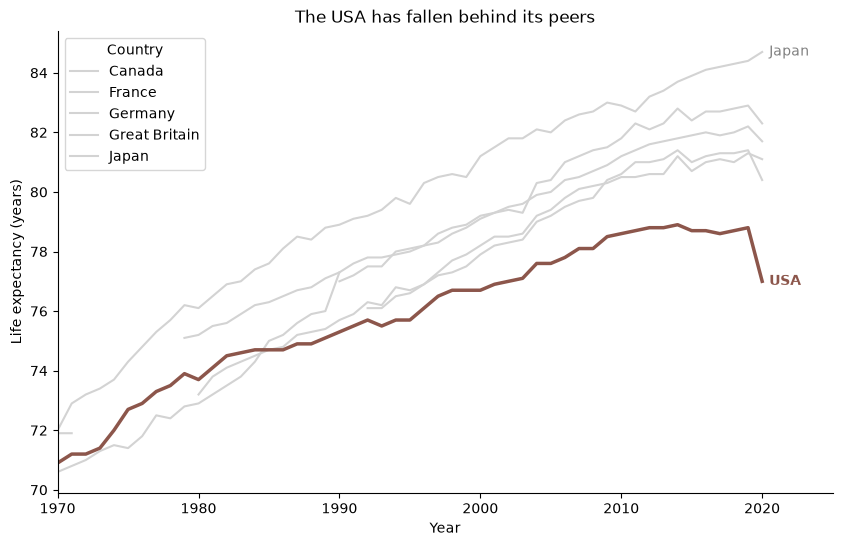

In [176]:
fig, ax = plt.subplots(figsize=(10, 6))

ax = life.iloc[:,:-1].plot(color='lightgray', ax=ax)
life.iloc[:,-1].plot(color='tab:brown', ax=ax, linewidth=2.5)

ax.text(2020.5, life.USA.loc[2020], 'USA', color='tab:brown', va='center', fontweight='bold')
ax.text(2020.5, life.Japan.loc[2020], 'Japan', color='gray', va='center')

ax.set_xlim(1970, 2025)
ax.set_ylabel('Life expectancy (years)')
ax.set_title('The USA has fallen behind its peers')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Notice that the title is used to train the users' attention to what the plot *shows*.

```{tip}
A title that states the finding is an annotation too, and often the most important one.
```

## Annotating a set of plots

When a figure has **several panels**, some annotations belong to the figure rather than to any one axes.

| Method | Annotates |
|---|---|
| `fig.suptitle()` | a title over all the panels |
| `fig.supxlabel()`, `fig.supylabel()` | shared axis labels |
| `fig.text()` | text anywhere on the figure, in figure fractions |
| `fig.legend()` | one legend for all the panels |
| `ax.text(..., transform=ax.transAxes)` | panel letters, the same position in every panel |
| `ConnectionPatch` | a line from a point in one axes to a point in another |

Let's combine them.

The figure below shows the whole `flights` series, then zooms in on one year.

Lines connect the zoomed region in the overview to the detail panel.

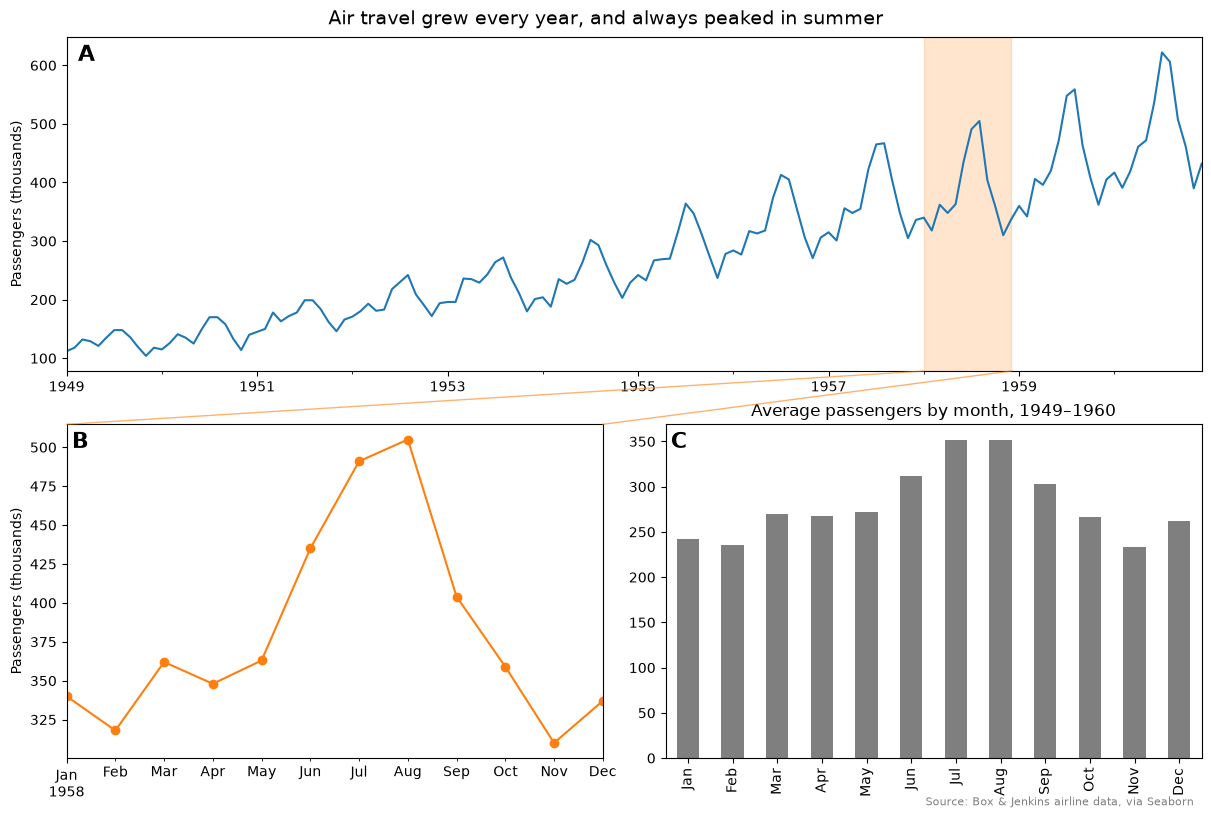

In [178]:
from matplotlib.patches import ConnectionPatch

fig, axd = plt.subplot_mosaic([['overview', 'overview'], ['detail', 'months']],
                              figsize=(12, 8), layout='constrained')

# Panel A: the whole series, with 1958 shaded
monthly.plot(ax=axd['overview'], color='tab:blue')
start, end = pd.Timestamp('1958-01-01'), pd.Timestamp('1958-12-01')
axd['overview'].axvspan(start, end, color='tab:orange', alpha=0.2)
axd['overview'].set_ylabel('Passengers (thousands)')
axd['overview'].set_xlabel('')

# Panel B: 1958 only
year = monthly[start:end]
year.plot(ax=axd['detail'], color='tab:orange', marker='o')
axd['detail'].set_ylabel('Passengers (thousands)')
axd['detail'].set_xlabel('')

# Panel C: the average month, all years
passengers.mean().plot.bar(ax=axd['months'], color='tab:gray')
axd['months'].set_xlabel('')

# Lines from the shaded span in A to the corners of B
for x_over, x_det in [(start, 0), (end, 1)]:
    x_num = axd['overview'].xaxis.convert_units(x_over)   # a date as an axis number
    con = ConnectionPatch(xyA=(x_num, 0), coordsA=axd['overview'].get_xaxis_transform(),
                          xyB=(x_det, 1), coordsB=axd['detail'].transAxes,
                          color='tab:orange', alpha=0.6)
    fig.add_artist(con)

# Panel letters in the same place on every axes
for letter, name in zip('ABC', ['overview', 'detail', 'months']):
    axd[name].text(0.01, 0.98, letter, transform=axd[name].transAxes,
                   fontsize=16, fontweight='bold', va='top')

axd['months'].set_title('Average passengers by month, 1949–1960')
fig.suptitle('Air travel grew every year, and always peaked in summer', fontsize=14)
fig.text(0.99, 0.0, 'Source: Box & Jenkins airline data, via Seaborn', ha='right', fontsize=8, color='gray')

plt.show()

Read the figure as a reader would.

The title states the finding.

Panel A shows the trend, and the shaded span tells us that Panel B is a closer look at 1958.

The connecting lines make that link explicit.

The panel letters let a caption or a paragraph refer to each part, as in "see Panel C".

The source line credits the data.

Every one of these marks is an annotation.

Notice how `ConnectionPatch` uses a different coordinate system at each end: a blended transform in Panel A and an axes fraction in Panel B.

It also needs plain numbers, not dates, so we convert each date with `xaxis.convert_units()`.

## Other Ways to Annotate

A few more tools are worth knowing.

- **Titles, labels, and legends.** `set_title()`, `set_xlabel()`, `set_ylabel()`, and `legend()` are annotations we use on every plot. `ax.set_title(loc='left')` places a title flush left, a common style in reports.
- **Math text.** Any label can include LaTeX math between dollar signs, as in `ax.set_xlabel(r'$\mu$ (g)')`.
- **Custom ticks.** `ax.set_xticks(positions, labels=...)` replaces tick labels with words, such as event names on a time axis.
- **Grid lines.** `ax.grid(axis='y')` adds light reference lines at every tick, for reading values.
- **Secondary axes.** `ax.secondary_xaxis()` and `ax.secondary_yaxis()` show a second scale for the same data, such as Celsius beside Fahrenheit.
- **Insets.** `ax.inset_axes([x, y, w, h])` places a small axes inside another, and `ax.indicate_inset_zoom()` draws the box and connecting lines for us.
- **Error bars and intervals.** `ax.errorbar()` and Seaborn's `errorbar` parameter mark uncertainty around a value.
- **Images and logos.** `fig.figimage()` and `ax.imshow()` can place an image, such as a logo or an icon.
- **Interactive tooltips.** In Plotly, which is in our environment, `hover_data` shows annotations when the reader points at a mark.

## When Annotations Mislead

Annotations are claims.

They tell readers what the data mean, and readers tend to believe them.

- **Implied causes.** A shaded span labeled with an event invites the reader to see the event as the cause of whatever happens inside it. Shade an event only when the connection is part of the argument, and say so in the text.
- **Arbitrary references.** A reference line looks like a standard. A mean, a legal limit, and a number we chose ourselves all look the same once drawn. Label every line with what it is.
- **Cherry-picked labels.** Labeling the extreme points draws attention to them. If they are unusual, say so; if the labels were chosen to support a story, the story is weaker than it looks.
- **Annotations that hide data.** A box or a label placed on top of the data covers the very observations it describes. Move it, make its background transparent, or point to the data from the outside.
- **Stale annotations.** Hand-typed values and positions stop being true when the data change. Compute them.
- **Clutter.** Every annotation competes with every other. If everything is labeled, the reader is back to reading a table.

## Summary

- An **annotation** is any mark that guides the reader's interpretation without encoding an observation.
- Annotations are placed in a **coordinate system**: data, axes fraction, figure fraction, or a blend.
- `ax.text()` writes text; `ha` and `va` align it relative to its point; `bbox` puts it in a box.
- `ax.annotate()` adds an arrow from `xytext` to `xy`; `textcoords='offset points'` places text relative to the point.
- Reference lines (`axhline`, `axvline`, `hlines`, `vlines`, `axline`) mark values; spans (`axvspan`, `axhspan`) mark intervals.
- `fill_between()` shades a range or a gap, and `where` shades it conditionally.
- `bar_label()` prints values on bars; patches circle or box a group; gray-and-color emphasis points the eye.
- Figure-level methods annotate a set of plots: `suptitle`, `supxlabel`, `fig.text`, panel letters, and `ConnectionPatch`.
- Every annotation is a claim. Compute it from the data, label it clearly, and use as few as the story needs.

| Task | Code |
|---|---|
| Text at a data point | `ax.text(x, y, 'label', ha='left', va='center')` |
| Text in a corner | `ax.text(0.02, 0.98, 'note', transform=ax.transAxes, va='top')` |
| Text in a box | `ax.text(..., bbox=dict(boxstyle='round', facecolor='white'))` |
| Callout with arrow | `ax.annotate('label', xy=(x, y), xytext=(x2, y2), arrowprops=dict(arrowstyle='->'))` |
| Offset label | `ax.annotate('label', xy=(x, y), xytext=(0, 10), textcoords='offset points')` |
| Horizontal or vertical line | `ax.axhline(y)`, `ax.axvline(x)` |
| Line at any angle | `ax.axline((x, y), slope=1)` |
| Label at a line's x, near the top | `ax.text(x, 0.95, 'label', transform=ax.get_xaxis_transform())` |
| Shaded interval | `ax.axvspan(x1, x2, alpha=0.2)` |
| Band between curves | `ax.fill_between(x, low, high)` |
| Conditional gap | `ax.fill_between(x, y1, y2, where=y1 > y2, interpolate=True)` |
| Values on bars | `ax.bar_label(ax.containers[0])` |
| Shape around a group | `ax.add_patch(Ellipse(center, w, h, fill=False))` |
| Title over panels | `fig.suptitle('...')` |
| Line between panels | `fig.add_artist(ConnectionPatch(xyA, xyB, coordsA, coordsB))` |